# Practical 4 — Prompt Engineering and RAG

**Enrollment:** BT24S05F007

## Aim
Design clear prompts and build a Retrieval Augmented Generation pipeline that answers only from retrieved evidence, so unsupported answers are reduced.

## Idea
A weak prompt leaves the model free to invent. A structured prompt fixes the role, format, and limits. RAG goes further: it first finds matching notes from a local knowledge base, then answers from those notes only. If nothing useful is retrieved, the system refuses instead of guessing.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

rng = np.random.default_rng(7)


## Prompt designs
Three prompts for the same topic. The first is vague. The second fixes role and format. The third shows few-shot labels so the model can copy the pattern.


In [2]:
vague = "Tell me about GANs."

structured = '''Role: Generative AI lab tutor.
Task: Explain a Generative Adversarial Network to a second-year CSE student.
Format: exactly 3 numbered steps.
Constraints: each step under 20 words; end with one classroom example.'''

few_shot = '''Classify the lab statement as Concept or Implementation.

Statement: "A discriminator scores real versus fake samples."
Label: Concept

Statement: "Train the generator for 200 epochs with Adam."
Label: Implementation

Statement: "Self-attention mixes token vectors using softmax weights."
Label:'''

print("Vague prompt:\n", vague)
print("\nStructured prompt:\n", structured)
print("\nFew-shot prompt:\n", few_shot)
print("\nDesign rules shown: role, format, length limit, and labeled examples.")


Vague prompt:
 Tell me about GANs.

Structured prompt:
 Role: Generative AI lab tutor.
Task: Explain a Generative Adversarial Network to a second-year CSE student.
Format: exactly 3 numbered steps.
Constraints: each step under 20 words; end with one classroom example.

Few-shot prompt:
 Classify the lab statement as Concept or Implementation.

Statement: "A discriminator scores real versus fake samples."
Label: Concept

Statement: "Train the generator for 200 epochs with Adam."
Label: Implementation

Statement: "Self-attention mixes token vectors using softmax weights."
Label:

Design rules shown: role, format, length limit, and labeled examples.


## Local knowledge base
Short notes about the course topics become the only evidence the answerer may use.


In [3]:
notes = [
    {
        "id": "N1",
        "topic": "Prompt design",
        "body": (
            "A useful prompt names the role, the task, the output format, "
            "and any hard limits such as length or required examples."
        ),
    },
    {
        "id": "N2",
        "topic": "Hallucination",
        "body": (
            "Hallucination means the model writes a confident claim that "
            "is not supported by the given evidence or training facts."
        ),
    },
    {
        "id": "N3",
        "topic": "RAG idea",
        "body": (
            "Retrieval Augmented Generation first finds related passages, "
            "then asks the generator to answer using only those passages."
        ),
    },
    {
        "id": "N4",
        "topic": "Vector search",
        "body": (
            "TF-IDF turns each note into a sparse vector. Cosine similarity "
            "ranks which notes are closest to the student question."
        ),
    },
    {
        "id": "N5",
        "topic": "Grounding rule",
        "body": (
            "If the best retrieved score stays below a threshold, the system "
            "must refuse. That refusal is how RAG limits unsupported answers."
        ),
    },
    {
        "id": "N6",
        "topic": "GAN reminder",
        "body": (
            "A GAN trains a generator against a discriminator so that fake "
            "samples become hard to tell apart from real ones."
        ),
    },
]

bodies = [item["body"] for item in notes]
encoder = TfidfVectorizer(stop_words="english")
note_matrix = encoder.fit_transform(bodies)
print("Notes stored:", len(notes))
print("TF-IDF matrix shape:", note_matrix.shape)


Notes stored: 6
TF-IDF matrix shape: (6, 65)


## Retriever
The question is encoded with the same vocabulary. The three highest cosine scores are returned.


Question: How can retrieval stop a language model from inventing unsupported facts?

#1 N2 | Hallucination | score=0.3015
Hallucination means the model writes a confident claim that is not supported by the given evidence or training facts.

#2 N5 | Grounding rule | score=0.1531
If the best retrieved score stays below a threshold, the system must refuse. That refusal is how RAG limits unsupported answers.

#3 N3 | RAG idea | score=0.1405
Retrieval Augmented Generation first finds related passages, then asks the generator to answer using only those passages.


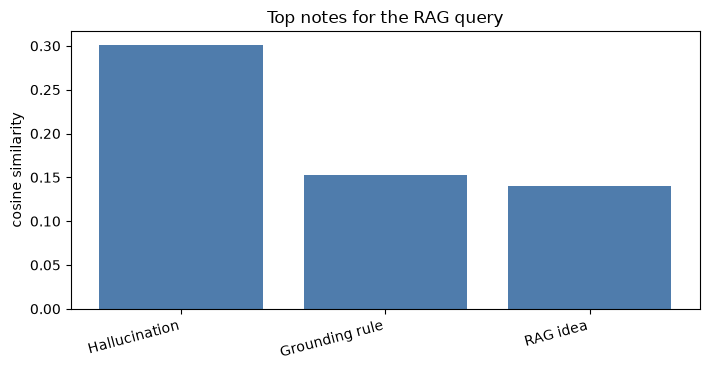

In [4]:
def fetch_notes(question, keep=3):
    question_vector = encoder.transform([question])
    scores = cosine_similarity(question_vector, note_matrix)[0]
    order = np.argsort(scores)[::-1][:keep]
    packed = []
    for index in order:
        packed.append(
            {
                "id": notes[index]["id"],
                "topic": notes[index]["topic"],
                "body": notes[index]["body"],
                "score": float(scores[index]),
            }
        )
    return packed

question = "How can retrieval stop a language model from inventing unsupported facts?"
hits = fetch_notes(question, keep=3)

print("Question:", question)
for rank, hit in enumerate(hits, start=1):
    print(f"\n#{rank} {hit['id']} | {hit['topic']} | score={hit['score']:.4f}")
    print(hit["body"])

fig, ax = plt.subplots(figsize=(7.2, 3.8))
ax.bar([hit["topic"] for hit in hits], [hit["score"] for hit in hits], color="#4f7cac")
ax.set_ylabel("cosine similarity")
ax.set_title("Top notes for the RAG query")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


## Grounded answerer
The generation stage here is a local rule: join the high-scoring notes, or refuse. No external API is required.


In [5]:
def answer_from_notes(question, keep=3, floor=0.12):
    ranked = fetch_notes(question, keep=keep)
    trusted = [item for item in ranked if item["score"] >= floor]
    if not trusted:
        reply = (
            "Refuse: none of the stored notes are close enough to this question, "
            "so inventing an answer would risk hallucination."
        )
        return reply, ranked
    joined = " ".join(item["body"] for item in trusted)
    sources = ", ".join(f"{item['id']}({item['topic']})" for item in trusted)
    reply = f"Grounded answer from notes:\n{joined}\n\nSources: {sources}"
    return reply, ranked

in_scope, _ = answer_from_notes(
    "How can retrieval stop a language model from inventing unsupported facts?"
)
out_of_scope, weak = answer_from_notes(
    "What was the exact stock price of a private startup yesterday afternoon?"
)

print("=== In-scope question ===")
print(in_scope)
print("\n=== Out-of-scope question ===")
print(out_of_scope)
print("\nWeak retrieval scores:", [round(item["score"], 4) for item in weak])


=== In-scope question ===
Grounded answer from notes:
Hallucination means the model writes a confident claim that is not supported by the given evidence or training facts. If the best retrieved score stays below a threshold, the system must refuse. That refusal is how RAG limits unsupported answers. Retrieval Augmented Generation first finds related passages, then asks the generator to answer using only those passages.

Sources: N2(Hallucination), N5(Grounding rule), N3(RAG idea)

=== Out-of-scope question ===
Refuse: none of the stored notes are close enough to this question, so inventing an answer would risk hallucination.

Weak retrieval scores: [0.0, 0.0, 0.0]


## Conclusion
Structured prompts reduce ambiguity. RAG adds evidence: TF-IDF retrieval picks related notes, and the answerer either quotes that evidence or refuses. The refusal on the stock-price question shows how grounding cuts hallucination when the knowledge base has nothing useful.


## Run results

Outputs captured from the executed notebook.

```
Vague prompt:
 Tell me about GANs.

Structured prompt:
 Role: Generative AI lab tutor.
Task: Explain a Generative Adversarial Network to a second-year CSE student.
Format: exactly 3 numbered steps.
Constraints: each step under 20 words; end with one classroom example.

Few-shot prompt:
 Classify the lab statement as Concept or Implementation.

Statement: "A discriminator scores real versus fake samples."
Label: Concept

Statement: "Train the generator for 200 epochs with Adam."
Label: Implementation

Statement: "Self-attention mixes token vectors using softmax weights."
Label:

Design rules shown: role, format, length limit, and labeled examples.
```

```
Notes stored: 6
TF-IDF matrix shape: (6, 65)
```

```
Question: How can retrieval stop a language model from inventing unsupported facts?

#1 N2 | Hallucination | score=0.3015
Hallucination means the model writes a confident claim that is not supported by the given evidence or training facts.

#2 N5 | Grounding rule | score=0.1531
If the best retrieved score stays below a threshold, the system must refuse. That refusal is how RAG limits unsupported answers.

#3 N3 | RAG idea | score=0.1405
Retrieval Augmented Generation first finds related passages, then asks the generator to answer using only those passages.
```

```
=== In-scope question ===
Grounded answer from notes:
Hallucination means the model writes a confident claim that is not supported by the given evidence or training facts. If the best retrieved score stays below a threshold, the system must refuse. That refusal is how RAG limits unsupported answers. Retrieval Augmented Generation first finds related passages, then asks the generator to answer using only those passages.

Sources: N2(Hallucination), N5(Grounding rule), N3(RAG idea)

=== Out-of-scope question ===
Refuse: none of the stored notes are close enough to this question, so inventing an answer would risk hallucination.

Weak retrieval scores: [0.0, 0.0, 0.0]
```

**figure 1**

![figure 1](results/GenAI_Practical_04_fig1.png)
